# Classificação de Tumores Cerebrais em MRI
## DCA3606 – Inteligência Artificial – Projeto Unidade 3

**Tema:** CNN (Redes Convolucionais) com Transfer Learning  
**Dataset:** Brain Tumor MRI Dataset (Kaggle) — 7.200 imagens, 4 classes  
**Baseline:** Random Forest sobre features HOG  
**Modelo Principal:** EfficientNetB0 pré-treinado (ImageNet) com fine-tuning

**Integrantes:**
-
-

---

### Roteiro do Notebook
1. Configuração e imports
2. Exploração dos dados (EDA)
3. Pré-processamento
4. Baseline — Random Forest + HOG
5. Modelo principal — EfficientNetB0 fine-tuned
6. Avaliação comparativa e métricas
7. Análise qualitativa (Grad-CAM, casos de erro)
8. Discussão e conclusão

---
## 1. Configuração e Imports

In [ ]:
# Instalação de dependências (descomente se necessário)
!pip install torch torchvision scikit-learn scikit-image matplotlib seaborn tqdm grad-cam opencv-python kagglehub

In [ ]:
#import kagglehub

# Download latest version
#path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

#print("Path to dataset files:", path)

In [7]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# CV / Image
import cv2
from skimage.feature import hog
from PIL import Image

# Sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, roc_auc_score, balanced_accuracy_score
)
from sklearn.preprocessing import label_binarize

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models
from torchvision.datasets import ImageFolder

# Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# Reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [ ]:
# (kagglehub já é instalado na célula de dependências acima)


In [8]:
# ─── CONFIGURAÇÃO DOS CAMINHOS ───────────────────────────────────────────────
# Usa a pasta local 'archive' (ao lado do notebook) se existir;
# caso contrário, baixa o dataset via kagglehub.
LOCAL_DATA = Path('archive')
if (LOCAL_DATA / 'Training').exists() and (LOCAL_DATA / 'Testing').exists():
    DATA_ROOT = LOCAL_DATA
else:
    import kagglehub
    DATA_ROOT = Path(kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset"))
print(f'Dataset em: {DATA_ROOT.resolve()}')
TRAIN_DIR = DATA_ROOT / 'Training'
TEST_DIR  = DATA_ROOT / 'Testing'

CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}

CLASS_NAMES_PT = {
    'glioma': 'Glioma',
    'meningioma': 'Meningioma',
    'notumor': 'Sem Tumor',
    'pituitary': 'Hipófise'
}

# Hiperparâmetros CNN
IMG_SIZE    = 224
BATCH_SIZE  = 32
NUM_WORKERS = 0 if os.name == 'nt' else 2  # Windows + Jupyter: workers do DataLoader costumam travar/ficar lentos
NUM_EPOCHS  = 20
LR_HEAD     = 1e-3   # taxa de aprendizado para a cabeça
LR_BACKBONE = 1e-4   # taxa para fine-tuning do backbone
UNFREEZE_EPOCH = 5   # época em que o backbone é descongelado
VAL_SPLIT   = 0.15   # fração do treino reservada para validação (early stopping)
CKPT_PATH   = 'diagnosAI_efficientnetb0.pth'  # checkpoint do melhor modelo

print('Configuração carregada.')
print(f'Classes: {CLASSES}')

Dataset em: C:\Users\nasci\OneDrive\Documentos\Estudos\IA\Tentativa3\archive
Configuração carregada.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


---
## 2. Exploração dos Dados (EDA)

In [9]:
def count_images(base_dir, classes):
    """Conta imagens por classe em um diretório."""
    counts = {}
    for cls in classes:
        path = base_dir / cls
        counts[cls] = len(list(path.glob('*')))
    return counts

train_counts = count_images(TRAIN_DIR, CLASSES)
test_counts  = count_images(TEST_DIR, CLASSES)

print('Distribuição do dataset:')
print(f'{"Classe":<15} {"Treino":>10} {"Teste":>10} {"Total":>10}')
print('-' * 47)
for cls in CLASSES:
    total = train_counts[cls] + test_counts[cls]
    print(f'{cls:<15} {train_counts[cls]:>10} {test_counts[cls]:>10} {total:>10}')
print('-' * 47)
print(f'{"TOTAL":<15} {sum(train_counts.values()):>10} {sum(test_counts.values()):>10} {sum(train_counts.values())+sum(test_counts.values()):>10}')

Distribuição do dataset:
Classe              Treino      Teste      Total
-----------------------------------------------
glioma                1400        400       1800
meningioma            1400        400       1800
notumor               1400        400       1800
pituitary             1400        400       1800
-----------------------------------------------
TOTAL                 5600       1600       7200


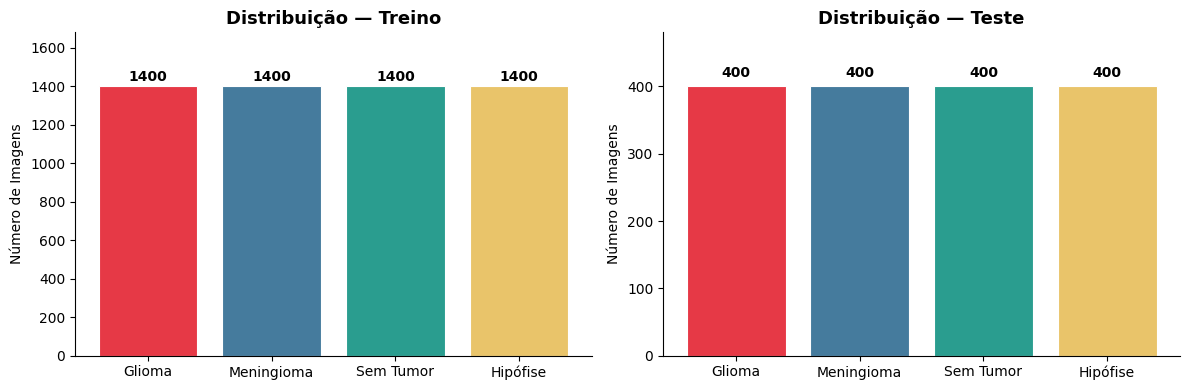

Classes balanceadas: sem necessidade de oversampling.


In [10]:
# Gráfico de distribuição de classes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ['#E63946', '#457B9D', '#2A9D8F', '#E9C46A']

for ax, (counts, title) in zip(axes, [(train_counts, 'Treino'), (test_counts, 'Teste')]):
    bars = ax.bar([CLASS_NAMES_PT[c] for c in CLASSES],
                  [counts[c] for c in CLASSES],
                  color=colors, edgecolor='white', linewidth=0.8)
    ax.set_title(f'Distribuição — {title}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Número de Imagens')
    ax.set_ylim(0, max(counts.values()) * 1.2)
    for bar, val in zip(bars, counts.values()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                str(val), ha='center', va='bottom', fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('distribuicao_classes.png', dpi=150, bbox_inches='tight')
plt.show()
print('Classes balanceadas: sem necessidade de oversampling.')

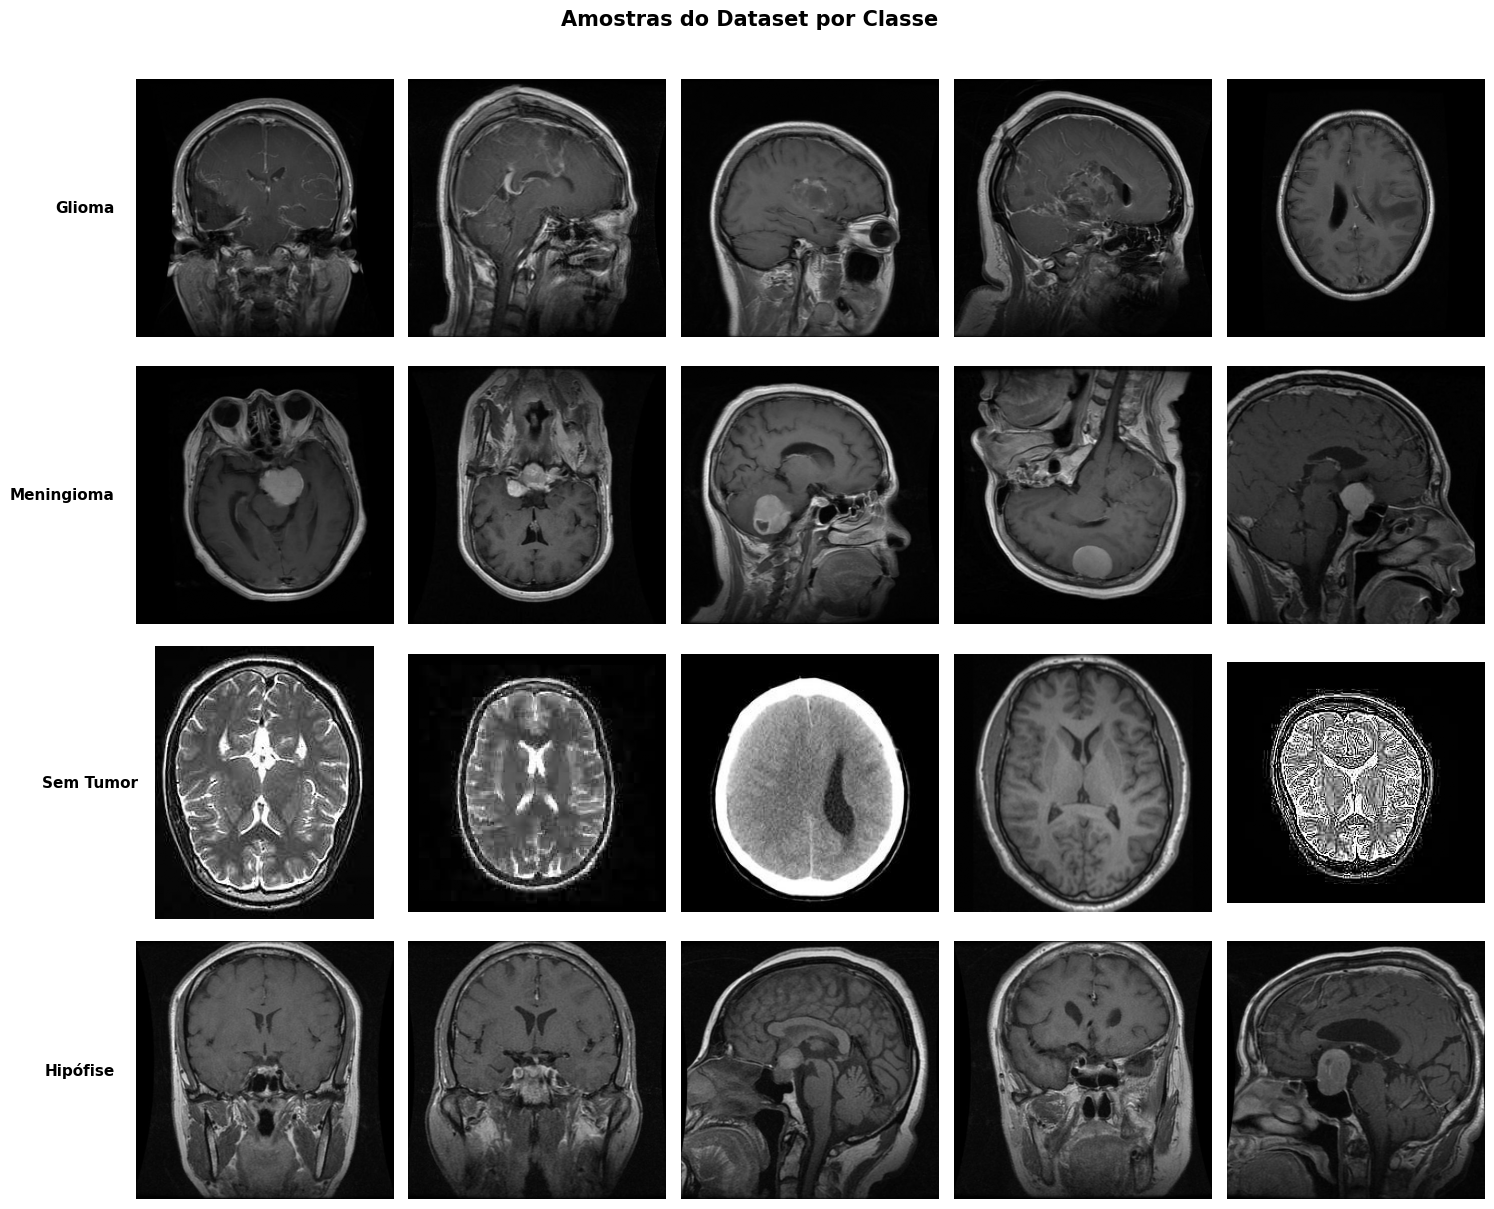

In [11]:
# Amostras visuais por classe
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
fig.suptitle('Amostras do Dataset por Classe', fontsize=15, fontweight='bold', y=1.01)

for row, cls in enumerate(CLASSES):
    imgs = list((TRAIN_DIR / cls).glob('*'))[:5]
    for col, img_path in enumerate(imgs):
        img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].axis('off')
        if col == 0:
            # set_ylabel não aparece com axis('off'); usa ax.text
            axes[row, col].text(-0.08, 0.5, CLASS_NAMES_PT[cls], fontsize=11,
                                fontweight='bold', ha='right', va='center',
                                transform=axes[row, col].transAxes)

plt.tight_layout()
plt.savefig('amostras_dataset.png', dpi=150, bbox_inches='tight')
plt.show()

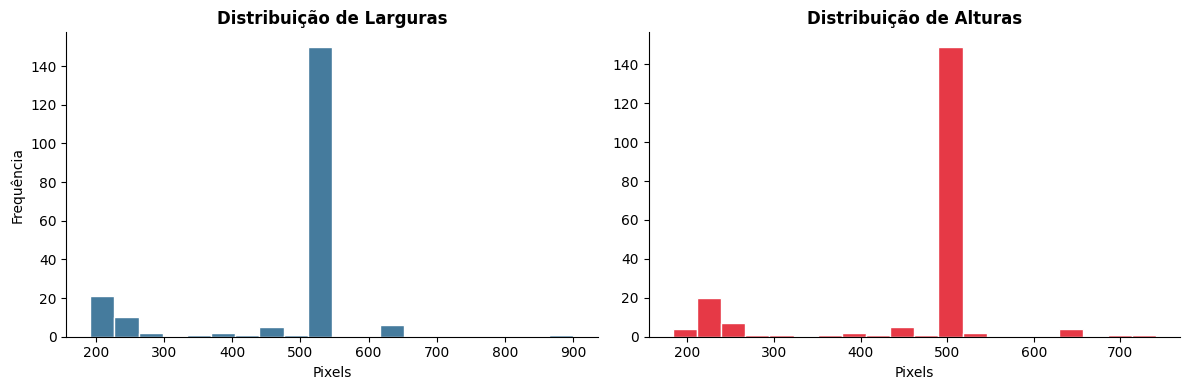

Largura  — min: 192, max: 900, média: 466
Altura   — min: 183, max: 741, média: 466
→ Imagens serão redimensionadas para 224×224 px.


In [12]:
# Análise de tamanhos de imagem
sizes = []
sample_paths = []
for cls in CLASSES:
    paths = list((TRAIN_DIR / cls).glob('*'))[:50]
    sample_paths.extend(paths)
    for p in paths:
        try:
            img = Image.open(p)
            sizes.append(img.size)
        except:
            pass

widths  = [s[0] for s in sizes]
heights = [s[1] for s in sizes]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(widths, bins=20, color='#457B9D', edgecolor='white')
axes[0].set_title('Distribuição de Larguras', fontweight='bold')
axes[0].set_xlabel('Pixels'); axes[0].set_ylabel('Frequência')
axes[1].hist(heights, bins=20, color='#E63946', edgecolor='white')
axes[1].set_title('Distribuição de Alturas', fontweight='bold')
axes[1].set_xlabel('Pixels')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('distribuicao_tamanhos.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Largura  — min: {min(widths)}, max: {max(widths)}, média: {np.mean(widths):.0f}')
print(f'Altura   — min: {min(heights)}, max: {max(heights)}, média: {np.mean(heights):.0f}')
print(f'→ Imagens serão redimensionadas para {IMG_SIZE}×{IMG_SIZE} px.')

---
## 3. Pré-processamento

### Estratégia
- **Remoção de margens:** crop automático baseado em threshold de Otsu para eliminar bordas pretas
- **Redimensionamento:** 224×224 px (padrão ImageNet)
- **Normalização:** média e desvio padrão do ImageNet (para o modelo pré-treinado)
- **Augmentação** (apenas treino): flip horizontal, rotação ±15°, ajuste de brilho/contraste

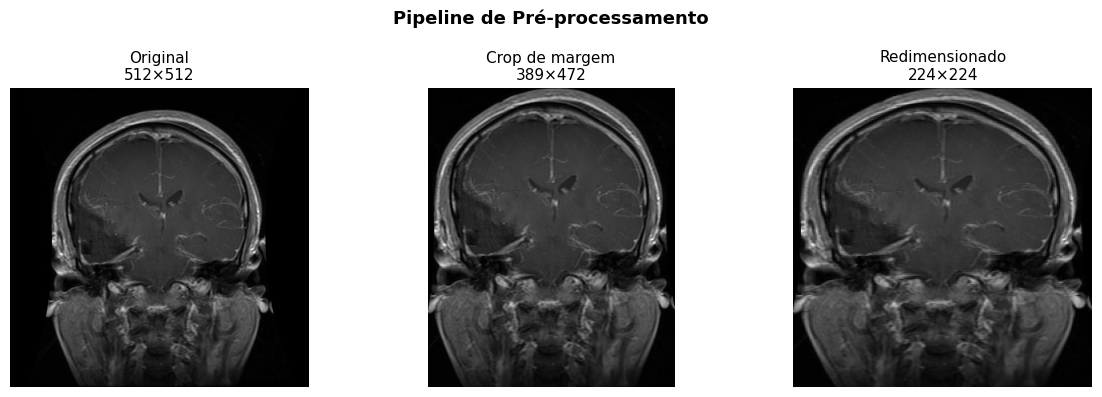

In [13]:
def remove_margins(img_bgr):
    """
    Remove margens pretas da imagem MRI usando threshold de Otsu.
    Retorna a imagem cropada em BGR.
    """
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return img_bgr
    x, y, w, h = cv2.boundingRect(max(contours, key=cv2.contourArea))
    return img_bgr[y:y+h, x:x+w]


# Exemplo visual do pré-processamento
sample_img_path = list((TRAIN_DIR / 'glioma').glob('*'))[0]
img_bgr  = cv2.imread(str(sample_img_path))
img_crop = remove_margins(img_bgr)
img_res  = cv2.resize(img_crop, (IMG_SIZE, IMG_SIZE))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle('Pipeline de Pré-processamento', fontsize=13, fontweight='bold')
for ax, (img, title) in zip(axes, [
    (cv2.cvtColor(img_bgr,  cv2.COLOR_BGR2RGB), f'Original\n{img_bgr.shape[1]}×{img_bgr.shape[0]}'),
    (cv2.cvtColor(img_crop, cv2.COLOR_BGR2RGB), f'Crop de margem\n{img_crop.shape[1]}×{img_crop.shape[0]}'),
    (cv2.cvtColor(img_res,  cv2.COLOR_BGR2RGB), f'Redimensionado\n{IMG_SIZE}×{IMG_SIZE}'),
]):
    ax.imshow(img)
    ax.set_title(title, fontsize=11)
    ax.axis('off')
plt.tight_layout()
plt.savefig('preprocessing_pipeline.png', dpi=150, bbox_inches='tight')
plt.show()

In [14]:
# Transforms para a CNN
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class BrainTumorDataset(Dataset):
    """
    Dataset customizado que aplica remoção de margem antes do transform.
    """
    def __init__(self, root_dir=None, classes=None, transform=None, samples=None):
        self.transform = transform
        if samples is not None:
            self.samples = list(samples)
        else:
            self.samples = []
            for label, cls in enumerate(classes):
                cls_dir = Path(root_dir) / cls
                for img_path in sorted(cls_dir.glob('*')):
                    self.samples.append((str(img_path), label))
            random.shuffle(self.samples)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img_bgr = cv2.imread(path)
        if img_bgr is None:
            img_bgr = np.zeros((224, 224, 3), dtype=np.uint8)
        img_bgr  = remove_margins(img_bgr)
        img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_pil  = Image.fromarray(img_rgb)
        if self.transform:
            img_pil = self.transform(img_pil)
        return img_pil, label


# Split estratificado treino/validação: a validação é usada para early stopping e
# seleção do melhor checkpoint. O conjunto de TESTE só é usado na avaliação final
# (evita vazamento de dados / métrica otimista).
from sklearn.model_selection import train_test_split

_full_train = BrainTumorDataset(TRAIN_DIR, CLASSES)
_labels = [lbl for _, lbl in _full_train.samples]
train_samples, val_samples = train_test_split(
    _full_train.samples, test_size=VAL_SPLIT, stratify=_labels, random_state=SEED)

train_dataset = BrainTumorDataset(samples=train_samples, transform=train_transforms)
val_dataset   = BrainTumorDataset(samples=val_samples,   transform=test_transforms)  # sem augmentação
test_dataset  = BrainTumorDataset(TEST_DIR, CLASSES, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

print(f'Treino: {len(train_dataset)} | Validação: {len(val_dataset)} | Teste: {len(test_dataset)}')
print(f'Batches — treino: {len(train_loader)} | validação: {len(val_loader)} | teste: {len(test_loader)}')

Treino: 4760 | Validação: 840 | Teste: 1600
Batches — treino: 149 | validação: 27 | teste: 50


---
## 4. Baseline — Random Forest com features HOG

O baseline utiliza **Histogram of Oriented Gradients (HOG)** como descritor de textura/forma, seguido de um classificador **Random Forest**. HOG captura a estrutura local de gradientes — adequado para distinguir padrões grosseiros entre classes.

> Esta é a abordagem clássica pré-deep-learning para classificação de imagens médicas.

In [15]:
HOG_IMG_SIZE = 128
# Dimensão do vetor HOG: (128/8 - 1)^2 blocos * (2*2*9) = 15*15*36 = 8100
HOG_DIM = ((HOG_IMG_SIZE // 8) - 1) ** 2 * (2 * 2 * 9)


def extract_hog_features(img_path, img_size=HOG_IMG_SIZE):
    """
    Carrega uma imagem, aplica crop de margem e extrai features HOG.
    Usa tamanho menor (128) para o baseline — mais rápido, igualmente representativo.
    """
    img_bgr = cv2.imread(str(img_path))
    if img_bgr is None:
        return np.zeros(HOG_DIM)
    img_bgr  = remove_margins(img_bgr)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    img_res  = cv2.resize(img_gray, (img_size, img_size))
    features = hog(
        img_res,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        transform_sqrt=True,
        feature_vector=True
    )
    return features


def load_hog_dataset(base_dir, classes):
    X, y = [], []
    for label, cls in enumerate(classes):
        paths = list((Path(base_dir) / cls).glob('*'))
        for p in tqdm(paths, desc=f'  HOG [{cls}]', leave=False):
            feat = extract_hog_features(p)
            X.append(feat)
            y.append(label)
    return np.array(X), np.array(y)


print('Extraindo features HOG — Treino...')
X_train_hog, y_train_hog = load_hog_dataset(TRAIN_DIR, CLASSES)
print('Extraindo features HOG — Teste...')
X_test_hog, y_test_hog = load_hog_dataset(TEST_DIR, CLASSES)

print(f'\nShape treino: {X_train_hog.shape} | Shape teste: {X_test_hog.shape}')

Extraindo features HOG — Treino...


Extraindo features HOG — Teste...



Shape treino: (5600, 8100) | Shape teste: (1600, 8100)


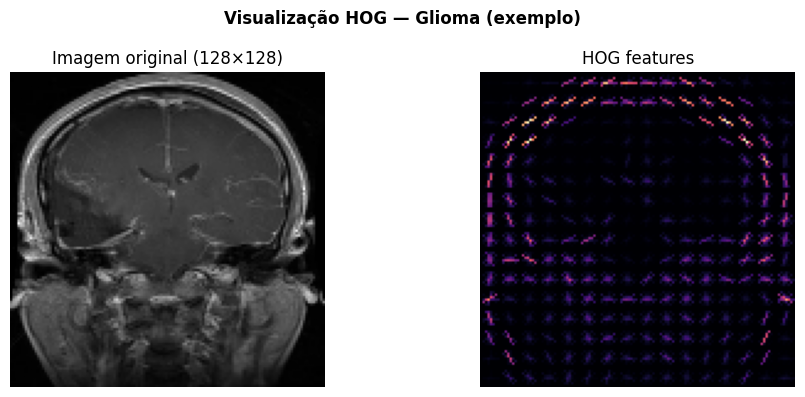

In [16]:
# Exemplo visual de feature HOG
from skimage.feature import hog as skimage_hog
from skimage import exposure

sample_path = list((TRAIN_DIR / 'glioma').glob('*'))[0]
img_bgr  = cv2.imread(str(sample_path))
img_bgr  = remove_margins(img_bgr)
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
img_res  = cv2.resize(img_gray, (128, 128))

_, hog_img = skimage_hog(img_res, orientations=9, pixels_per_cell=(8, 8),
                          cells_per_block=(2, 2), transform_sqrt=True,
                          visualize=True, feature_vector=True)
hog_img_rescaled = exposure.rescale_intensity(hog_img, in_range=(0, 10))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle('Visualização HOG — Glioma (exemplo)', fontsize=12, fontweight='bold')
axes[0].imshow(img_res, cmap='gray'); axes[0].set_title('Imagem original (128×128)')
axes[1].imshow(hog_img_rescaled, cmap='magma'); axes[1].set_title('HOG features')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.savefig('hog_visualizacao.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# Treinamento do Random Forest
print('Treinando Random Forest...')
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    n_jobs=-1,
    random_state=SEED,
    class_weight='balanced'
)
rf_model.fit(X_train_hog, y_train_hog)

# Predições
y_pred_rf   = rf_model.predict(X_test_hog)
y_proba_rf  = rf_model.predict_proba(X_test_hog)

# Métricas baseline
acc_rf      = accuracy_score(y_test_hog, y_pred_rf)
f1_rf       = f1_score(y_test_hog, y_pred_rf, average='macro')
bal_acc_rf  = balanced_accuracy_score(y_test_hog, y_pred_rf)

# AUC multiclasse (OvR)
auc_rf      = roc_auc_score(y_test_hog, y_proba_rf, multi_class='ovr', average='macro')

print('\n── Baseline: Random Forest + HOG ──────────────────')
print(f'  Acurácia:          {acc_rf:.4f}')
print(f'  Balanced Accuracy: {bal_acc_rf:.4f}')
print(f'  F1-macro:          {f1_rf:.4f}')
print(f'  AUC-ROC (macro):   {auc_rf:.4f}')
print()
print(classification_report(y_test_hog, y_pred_rf,
                             target_names=[CLASS_NAMES_PT[c] for c in CLASSES]))

Treinando Random Forest...

── Baseline: Random Forest + HOG ──────────────────
  Acurácia:          0.7981
  Balanced Accuracy: 0.7981
  F1-macro:          0.7912
  AUC-ROC (macro):   0.9379

              precision    recall  f1-score   support

      Glioma       0.75      0.66      0.70       400
  Meningioma       0.79      0.64      0.70       400
   Sem Tumor       0.83      0.98      0.90       400
    Hipófise       0.80      0.91      0.85       400

    accuracy                           0.80      1600
   macro avg       0.79      0.80      0.79      1600
weighted avg       0.79      0.80      0.79      1600



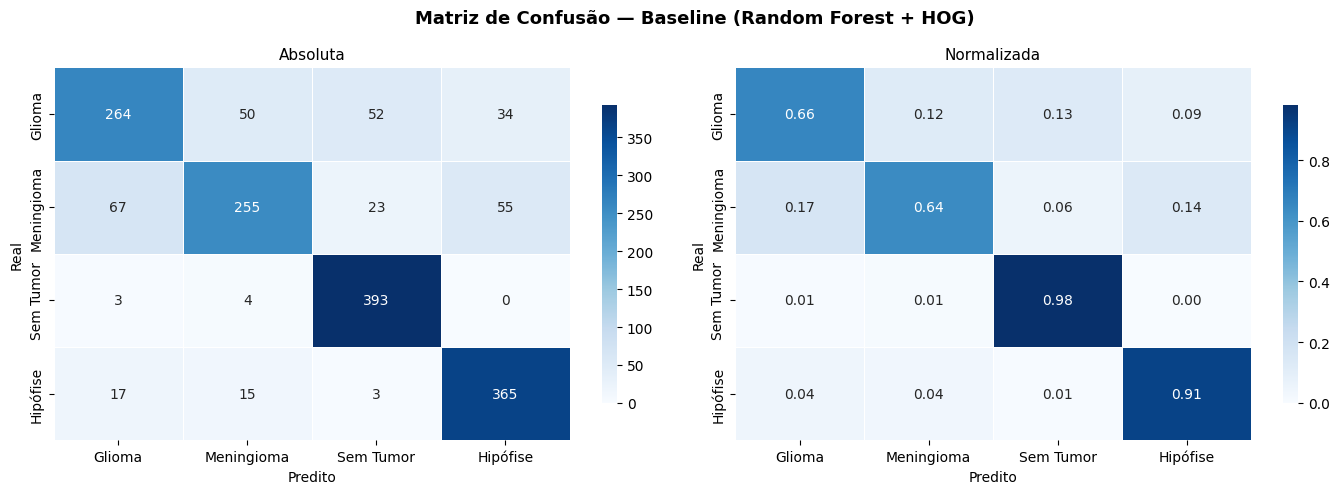

In [18]:
# Matriz de confusão — Baseline
def plot_confusion_matrix(y_true, y_pred, classes, title, filename):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(title, fontsize=13, fontweight='bold')

    for ax, (data, fmt, ttl) in zip(axes, [
        (cm,      'd',    'Absoluta'),
        (cm_norm, '.2f',  'Normalizada'),
    ]):
        sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues',
                    xticklabels=classes, yticklabels=classes,
                    ax=ax, linewidths=0.5, cbar_kws={'shrink': 0.8})
        ax.set_title(ttl, fontsize=11)
        ax.set_ylabel('Real')
        ax.set_xlabel('Predito')

    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

plot_confusion_matrix(
    y_test_hog, y_pred_rf,
    classes=[CLASS_NAMES_PT[c] for c in CLASSES],
    title='Matriz de Confusão — Baseline (Random Forest + HOG)',
    filename='cm_baseline.png'
)

---
## 5. Modelo Principal — EfficientNetB0 com Fine-tuning

### Justificativa da escolha
**EfficientNetB0** é o modelo pré-treinado mais adequado para este problema por:
- **Eficiência:** melhor acurácia por parâmetro da família EfficientNet (escalamento composto)
- **Tamanho:** ~5.3M parâmetros — treina bem em GPU com memória limitada
- **Generalização:** forte transfer learning de ImageNet para imagens médicas (literatura)
- **Alternativas descartadas:** ResNet50 (mais pesada, sem ganho proporcional), ViT (requer mais dados)

### Estratégia de treinamento
1. **Fase 1 (épocas 1–5):** backbone congelado, treina apenas a cabeça classificadora
2. **Fase 2 (épocas 6–20):** backbone descongelado com LR menor (fine-tuning completo)
3. **Validação:** 15% do treino (estratificado) para early stopping/seleção do checkpoint; o conjunto de teste só é usado na avaliação final

Total de parâmetros:     4,336,512
Parâmetros treináveis:   4,336,512
Cabeça classificadora:
Sequential(
  (0): Dropout(p=0.3, inplace=True)
  (1): Linear(in_features=1280, out_features=256, bias=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=256, out_features=4, bias=True)
)
Funções de treino/avaliação definidas.
Iniciando treinamento — 20 épocas
Fase 1 (backbone congelado): épocas 1–5
Fase 2 (fine-tuning completo): épocas 6–20
─────────────────────────────────────────────────────────────────
 Época  Loss Treino   Acc Treino   Loss Val    Acc Val         LR
─────────────────────────────────────────────────────────────────


     1       0.8013      0.7723     0.5982    0.8905   1.00e-03 ← melhor


     2       0.6901      0.8317     0.5932    0.8821   9.05e-04 ← melhor


     3       0.6499      0.8521     0.5554    0.9083   6.55e-04 ← melhor


     4       0.6294      0.8662     0.5507    0.9071   3.45e-04 ← melhor


     5       0.6177      0.8693     0.5505    0.9024   9.55e-05

  → Época 6: descongelando backbone (LR=0.0001)


... (11 outputs left out)

    17       0.3711      0.9962     0.3860    0.9845   1.65e-05


    18       0.3719      0.9962     0.3852    0.9833   9.55e-06 ← melhor


    19       0.3697      0.9975     0.3836    0.9845   4.32e-06 ← melhor


    20       0.3692      0.9979     0.3845    0.9821   1.09e-06
─────────────────────────────────────────────────────────────────

Melhor perda de validação: 0.3836 (Acurácia: 0.9845)


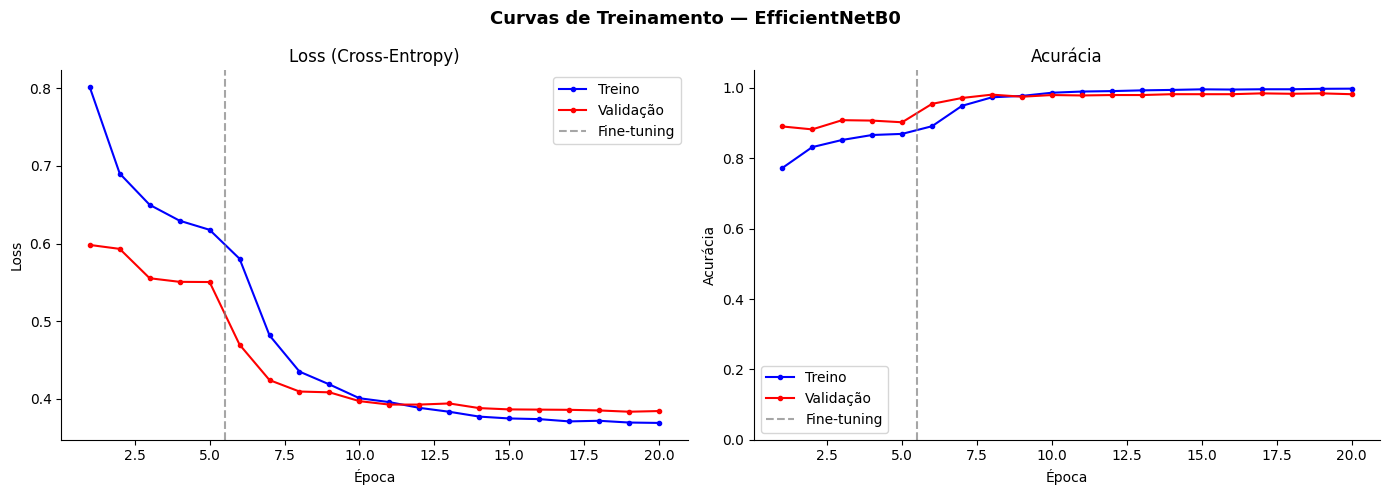

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision import models
from tqdm import tqdm

def build_efficientnet(num_classes=4, pretrained=True):
    weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
    model   = models.efficientnet_b0(weights=weights)

    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3, inplace=True),
        nn.Linear(in_features, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.2),
        nn.Linear(256, num_classes)
    )
    return model

def freeze_backbone(model):
    for name, param in model.named_parameters():
        if 'classifier' not in name:
            param.requires_grad = False

def unfreeze_backbone(model):
    for param in model.parameters():
        param.requires_grad = True

cnn_model = build_efficientnet(num_classes=len(CLASSES), pretrained=True)
cnn_model = cnn_model.to(DEVICE)

total_params    = sum(p.numel() for p in cnn_model.parameters())
trainable_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
print(f'Total de parâmetros:     {total_params:,}')
print(f'Parâmetros treináveis:   {trainable_params:,}')
print(f'Cabeça classificadora:\n{cnn_model.classifier}')

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    # Barra de progresso para o treino
    pbar = tqdm(loader, desc="Treinando Lotes", leave=False)
    
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total   += imgs.size(0)
        
        # Mostra a perda caindo em tempo real no VS Code
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
        
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []
    
    # Barra de progresso para a validação
    pbar = tqdm(loader, desc="Avaliando Lotes", leave=False)
    
    for imgs, labels in pbar:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss    = criterion(outputs, labels)
        probs   = torch.softmax(outputs, dim=1)
        
        running_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total   += imgs.size(0)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
        
    return (running_loss / total, correct / total,
            np.array(all_preds), np.array(all_labels), np.array(all_probs))

print('Funções de treino/avaliação definidas.')

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

freeze_backbone(cnn_model)
optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, cnn_model.parameters()),
    lr=LR_HEAD, weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=UNFREEZE_EPOCH)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

# Early Stopping (monitora a perda de validação)
class EarlyStopping:
    def __init__(self, patience=7, min_delta=1e-3):
        self.patience, self.min_delta = patience, min_delta
        self.best = float('inf')
        self.counter = 0
        self.best_state = None

    def reset_counter(self):
        self.counter = 0

    def step(self, val_loss, model):
        """Retorna (melhorou, deve_parar)."""
        if val_loss < self.best - self.min_delta:
            self.best = val_loss
            self.counter = 0
            # guarda na CPU para não ocupar memória da GPU
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            return True, False
        self.counter += 1
        return False, self.counter >= self.patience

early_stop = EarlyStopping(patience=7, min_delta=1e-3)
best_val_acc = 0.0

print(f'Iniciando treinamento — {NUM_EPOCHS} épocas')
print(f'Fase 1 (backbone congelado): épocas 1–{UNFREEZE_EPOCH}')
print(f'Fase 2 (fine-tuning completo): épocas {UNFREEZE_EPOCH+1}–{NUM_EPOCHS}')
print('─' * 65)
print(f'{"Época":>6} {"Loss Treino":>12} {"Acc Treino":>12} {"Loss Val":>10} {"Acc Val":>10} {"LR":>10}')
print('─' * 65)

for epoch in range(1, NUM_EPOCHS + 1):
    if epoch == UNFREEZE_EPOCH + 1:
        print(f'\n  → Época {epoch}: descongelando backbone (LR={LR_BACKBONE})')
        unfreeze_backbone(cnn_model)
        early_stop.reset_counter()  # nova fase: a paciência recomeça
        optimizer = optim.AdamW([
            {'params': cnn_model.features.parameters(),    'lr': LR_BACKBONE},
            {'params': cnn_model.classifier.parameters(),  'lr': LR_HEAD},
        ], weight_decay=1e-4)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=NUM_EPOCHS - UNFREEZE_EPOCH)

    tr_loss, tr_acc = train_one_epoch(cnn_model, train_loader, criterion, optimizer, DEVICE)
    vl_loss, vl_acc, _, _, _ = evaluate(cnn_model, val_loader, criterion, DEVICE)  # validação (NÃO o teste)
    current_lr = optimizer.param_groups[0]['lr']  # LR usado nesta época (antes do scheduler.step)
    scheduler.step()

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(vl_loss)
    history['val_acc'].append(vl_acc)
    
    # Avaliação do Early Stopping
    improved, should_stop = early_stop.step(vl_loss, cnn_model)
    if improved:
        best_val_acc = vl_acc
        torch.save(early_stop.best_state, CKPT_PATH)
        marker = ' ← melhor'
    else:
        marker = ''

    print(f'{epoch:>6} {tr_loss:>12.4f} {tr_acc:>11.4f} {vl_loss:>10.4f} {vl_acc:>9.4f} {current_lr:>10.2e}{marker}')

    if should_stop:
        print(f"\nTreinamento interrompido (Early Stopping) na época {epoch}: "
              f"{early_stop.patience} épocas sem melhora na perda de validação.")
        break

print('─' * 65)
print(f'\nMelhor perda de validação: {early_stop.best:.4f} (Acurácia: {best_val_acc:.4f})')

# Carrega os pesos ótimos antes da geração dos gráficos
cnn_model.load_state_dict(early_stop.best_state)

epochs_run = range(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Curvas de Treinamento — EfficientNetB0', fontsize=13, fontweight='bold')

axes[0].plot(epochs_run, history['train_loss'], 'b-o', markersize=3, label='Treino')
axes[0].plot(epochs_run, history['val_loss'],   'r-o', markersize=3, label='Validação')
if UNFREEZE_EPOCH < len(epochs_run):
    axes[0].axvline(x=UNFREEZE_EPOCH + 0.5, color='gray', linestyle='--', alpha=0.7, label='Fine-tuning')
axes[0].set_title('Loss (Cross-Entropy)')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].spines[['top', 'right']].set_visible(False)

axes[1].plot(epochs_run, history['train_acc'], 'b-o', markersize=3, label='Treino')
axes[1].plot(epochs_run, history['val_acc'],   'r-o', markersize=3, label='Validação')
if UNFREEZE_EPOCH < len(epochs_run):
    axes[1].axvline(x=UNFREEZE_EPOCH + 0.5, color='gray', linestyle='--', alpha=0.7, label='Fine-tuning')
axes[1].set_title('Acurácia')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Acurácia')
axes[1].set_ylim(0, 1.05)
axes[1].legend(); axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('curvas_treinamento.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 6. Avaliação Comparativa e Métricas

In [20]:
# Carregar o melhor modelo e avaliar UMA vez no conjunto de teste
cnn_model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
_, acc_cnn, y_pred_cnn, y_true_cnn, y_proba_cnn = evaluate(
    cnn_model, test_loader, criterion, DEVICE)

f1_cnn      = f1_score(y_true_cnn, y_pred_cnn, average='macro')
bal_acc_cnn = balanced_accuracy_score(y_true_cnn, y_pred_cnn)
y_test_bin2 = label_binarize(y_true_cnn, classes=list(range(len(CLASSES))))
auc_cnn     = roc_auc_score(y_test_bin2, y_proba_cnn, multi_class='ovr', average='macro')

print('── Modelo Principal: EfficientNetB0 fine-tuned ────────')
print(f'  Acurácia:          {acc_cnn:.4f}')
print(f'  Balanced Accuracy: {bal_acc_cnn:.4f}')
print(f'  F1-macro:          {f1_cnn:.4f}')
print(f'  AUC-ROC (macro):   {auc_cnn:.4f}')
print()
print(classification_report(y_true_cnn, y_pred_cnn,
                             target_names=[CLASS_NAMES_PT[c] for c in CLASSES]))

── Modelo Principal: EfficientNetB0 fine-tuned ────────
  Acurácia:          0.9563
  Balanced Accuracy: 0.9563
  F1-macro:          0.9554
  AUC-ROC (macro):   0.9952

              precision    recall  f1-score   support

      Glioma       1.00      0.84      0.91       400
  Meningioma       0.91      0.98      0.94       400
   Sem Tumor       0.95      1.00      0.97       400
    Hipófise       0.99      1.00      0.99       400

    accuracy                           0.96      1600
   macro avg       0.96      0.96      0.96      1600
weighted avg       0.96      0.96      0.96      1600



In [21]:
# Tabela comparativa
print('\n' + '═' * 62)
print(f'  {"Modelo / Configuração":<28} {"Acurácia":>8} {"Bal.Acc":>8} {"F1-macro":>9} {"AUC-ROC":>8}')
print('─' * 62)
print(f'  {"Baseline (RF + HOG)":<28} {acc_rf:>8.4f} {bal_acc_rf:>8.4f} {f1_rf:>9.4f} {auc_rf:>8.4f}')
print(f'  {"EfficientNetB0 (fine-tuned)":<28} {acc_cnn:>8.4f} {bal_acc_cnn:>8.4f} {f1_cnn:>9.4f} {auc_cnn:>8.4f}')
print('═' * 62)

delta_acc = acc_cnn - acc_rf
delta_f1  = f1_cnn  - f1_rf
print(f'\n  Ganho absoluto em Acurácia: {delta_acc:+.4f} ({delta_acc*100:+.2f} p.p.)')
print(f'  Ganho absoluto em F1-macro: {delta_f1:+.4f} ({delta_f1*100:+.2f} p.p.)')


══════════════════════════════════════════════════════════════
  Modelo / Configuração        Acurácia  Bal.Acc  F1-macro  AUC-ROC
──────────────────────────────────────────────────────────────
  Baseline (RF + HOG)            0.7981   0.7981    0.7912   0.9379
  EfficientNetB0 (fine-tuned)    0.9563   0.9563    0.9554   0.9952
══════════════════════════════════════════════════════════════

  Ganho absoluto em Acurácia: +0.1581 (+15.81 p.p.)
  Ganho absoluto em F1-macro: +0.1642 (+16.42 p.p.)


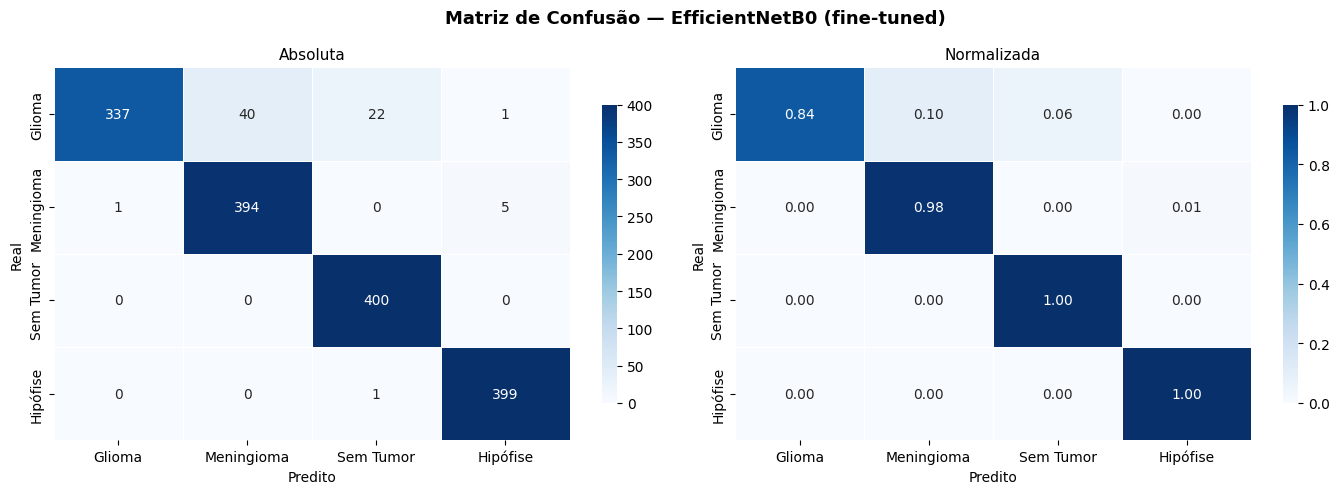

In [22]:
# Matriz de confusão — CNN
plot_confusion_matrix(
    y_true_cnn, y_pred_cnn,
    classes=[CLASS_NAMES_PT[c] for c in CLASSES],
    title='Matriz de Confusão — EfficientNetB0 (fine-tuned)',
    filename='cm_cnn.png'
)

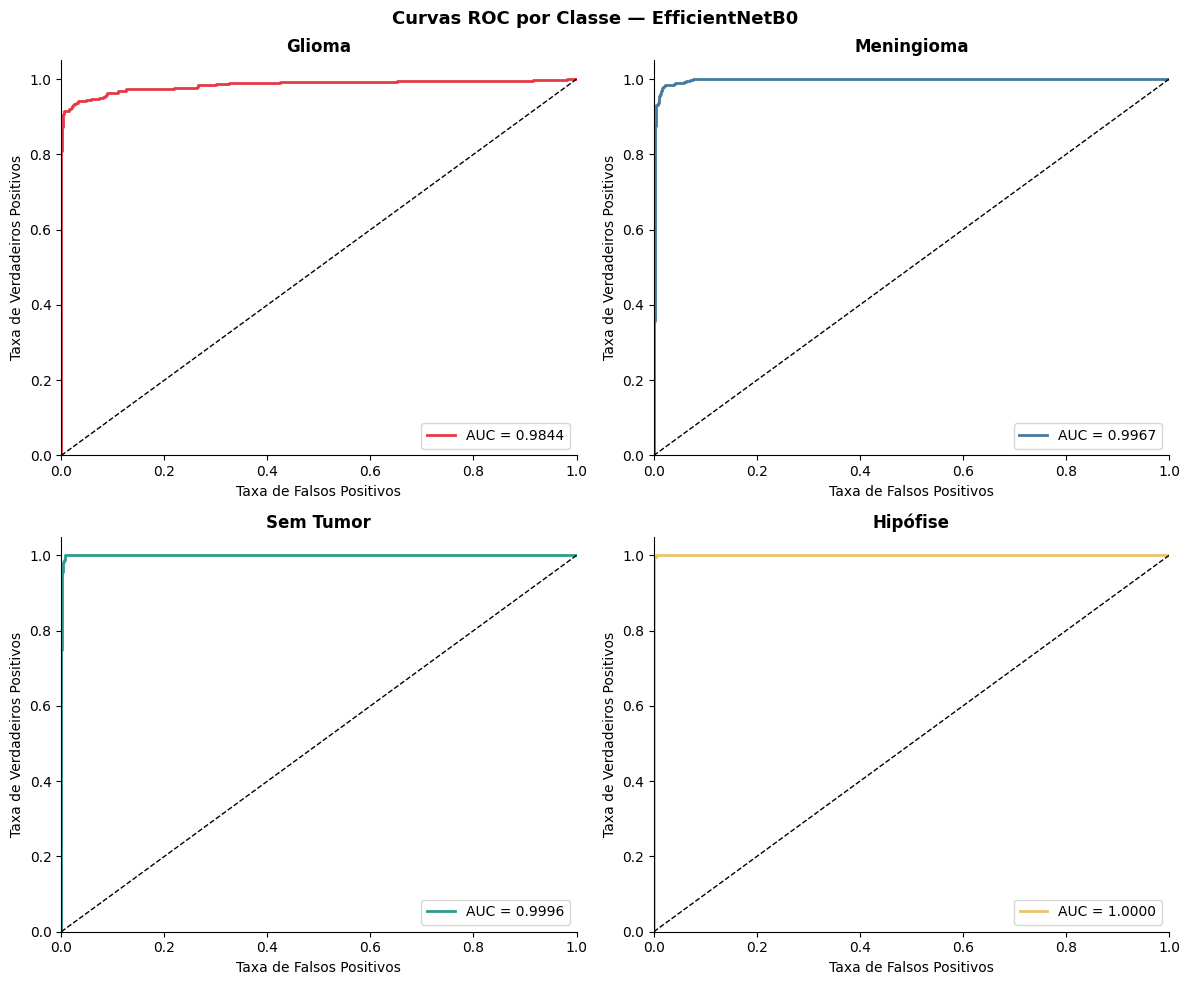

In [23]:
# Curvas ROC por classe
from sklearn.metrics import roc_curve, auc

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Curvas ROC por Classe — EfficientNetB0', fontsize=13, fontweight='bold')
colors = ['#E63946', '#457B9D', '#2A9D8F', '#E9C46A']

for i, (cls, ax, color) in enumerate(zip(CLASSES, axes.flatten(), colors)):
    fpr, tpr, _ = roc_curve(y_test_bin2[:, i], y_proba_cnn[:, i])
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, lw=2, label=f'AUC = {roc_auc:.4f}')
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_xlim([0, 1]); ax.set_ylim([0, 1.05])
    ax.set_xlabel('Taxa de Falsos Positivos')
    ax.set_ylabel('Taxa de Verdadeiros Positivos')
    ax.set_title(f'{CLASS_NAMES_PT[cls]}', fontweight='bold')
    ax.legend(loc='lower right')
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('roc_curves_cnn.png', dpi=150, bbox_inches='tight')
plt.show()

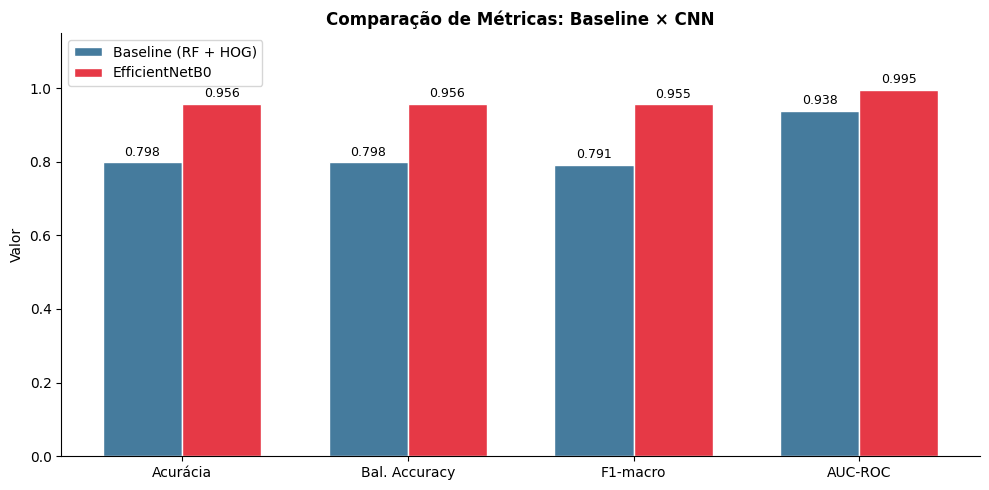

In [24]:
# Comparação visual side-by-side das métricas
metrics_names = ['Acurácia', 'Bal. Accuracy', 'F1-macro', 'AUC-ROC']
rf_values  = [acc_rf,  bal_acc_rf,  f1_rf,  auc_rf]
cnn_values = [acc_cnn, bal_acc_cnn, f1_cnn, auc_cnn]

x      = np.arange(len(metrics_names))
width  = 0.35
fig, ax = plt.subplots(figsize=(10, 5))

bars_rf  = ax.bar(x - width/2, rf_values,  width, label='Baseline (RF + HOG)',
                   color='#457B9D', edgecolor='white')
bars_cnn = ax.bar(x + width/2, cnn_values, width, label='EfficientNetB0',
                   color='#E63946', edgecolor='white')

ax.set_ylabel('Valor'); ax.set_title('Comparação de Métricas: Baseline × CNN', fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(metrics_names)
ax.set_ylim(0, 1.15)
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

for bar in list(bars_rf) + list(bars_cnn):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('comparacao_metricas.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 7. Análise Qualitativa

### 7.1 Grad-CAM — o que o modelo "olha"?

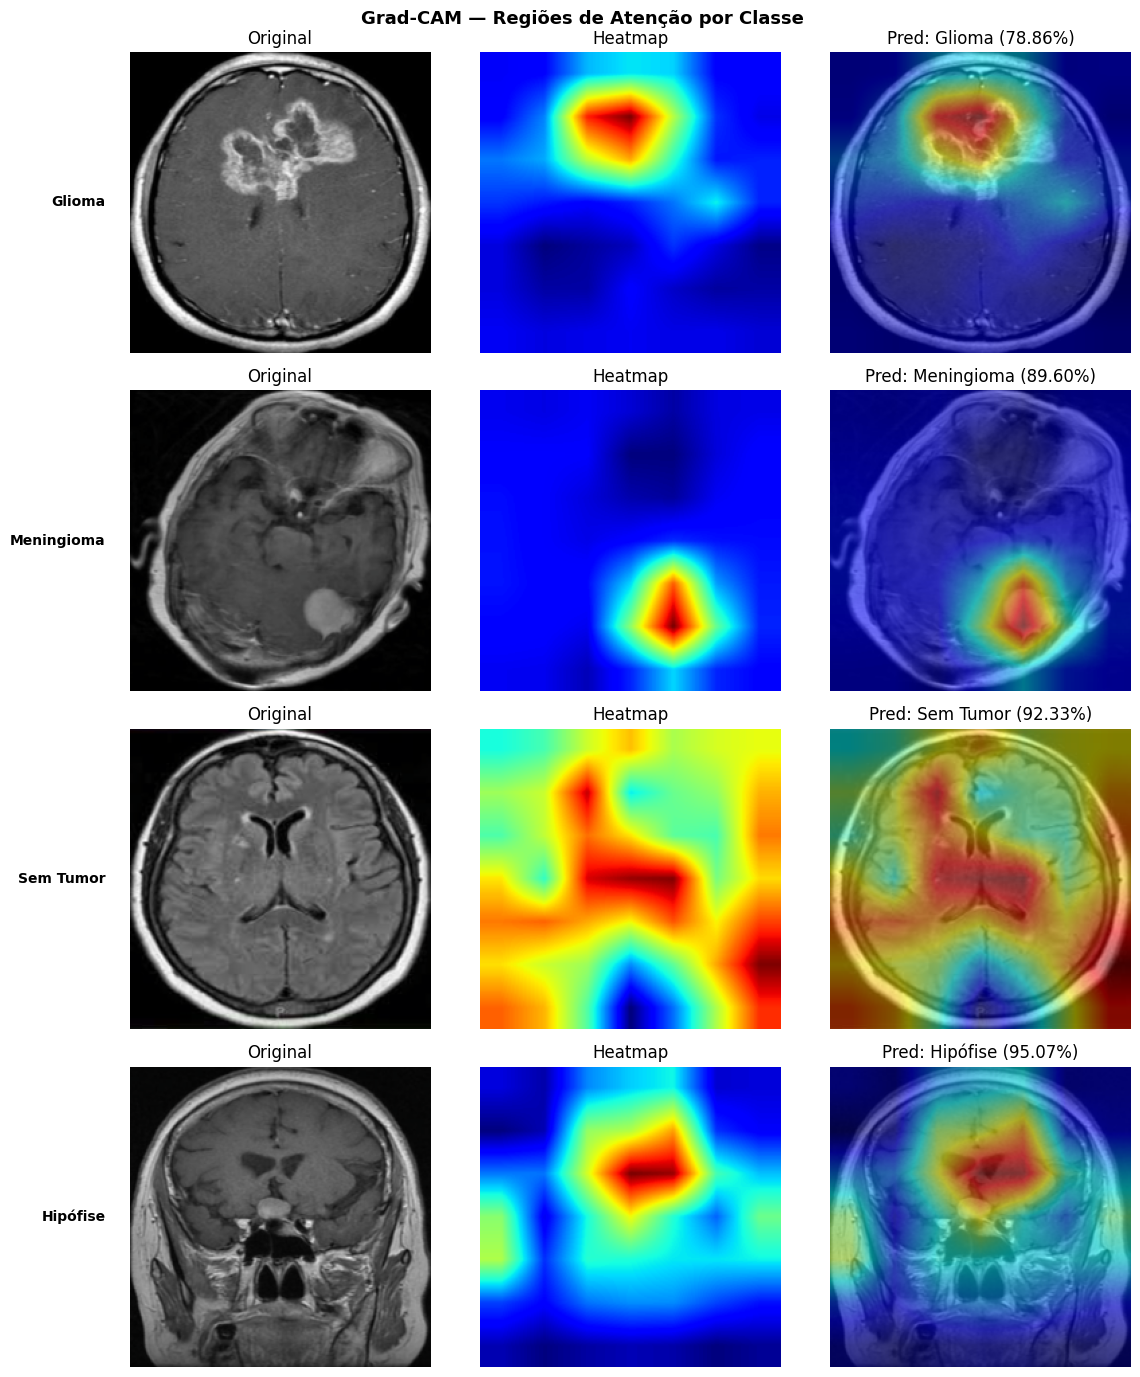

In [25]:
def get_gradcam_image(model, img_tensor, target_class=None):
    """
    Gera o mapa de ativação Grad-CAM para uma imagem.
    Retorna a imagem RGB com o heatmap sobreposto.
    """
    # Última camada convolucional do EfficientNetB0
    target_layers = [model.features[-1]]
    targets = [ClassifierOutputTarget(target_class)] if target_class is not None else None
    # 'with' garante a remoção dos hooks (evita acúmulo de hooks a cada chamada)
    with GradCAM(model=model, target_layers=target_layers) as cam:
        grayscale_cam = cam(input_tensor=img_tensor.unsqueeze(0).to(DEVICE), targets=targets)
    grayscale_cam = grayscale_cam[0]

    # Desnormaliza para visualização
    mean = np.array(IMAGENET_MEAN)
    std  = np.array(IMAGENET_STD)
    img_np = img_tensor.permute(1, 2, 0).numpy()
    img_np = std * img_np + mean
    img_np = np.clip(img_np, 0, 1).astype(np.float32)

    cam_image = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)
    return img_np, cam_image, grayscale_cam


# Grad-CAM para um exemplo de cada classe
cnn_model.eval()
fig, axes = plt.subplots(len(CLASSES), 3, figsize=(12, 14))
fig.suptitle('Grad-CAM — Regiões de Atenção por Classe', fontsize=13, fontweight='bold')

for row, cls in enumerate(CLASSES):
    # Pegar uma amostra do teste
    paths = list((TEST_DIR / cls).glob('*'))
    img_path = paths[0]

    img_bgr = cv2.imread(str(img_path))
    img_bgr = remove_margins(img_bgr)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_pil = Image.fromarray(img_rgb)
    img_tensor = test_transforms(img_pil)

    with torch.no_grad():
        logits = cnn_model(img_tensor.unsqueeze(0).to(DEVICE))
        pred_idx = logits.argmax(1).item()
        confidence = torch.softmax(logits, dim=1)[0, pred_idx].item()

    img_np, cam_img, heatmap = get_gradcam_image(cnn_model, img_tensor, target_class=pred_idx)

    axes[row, 0].imshow(img_np); axes[row, 0].set_title('Original')
    axes[row, 1].imshow(heatmap, cmap='jet'); axes[row, 1].set_title('Heatmap')
    axes[row, 2].imshow(cam_img)
    axes[row, 2].set_title(f'Pred: {CLASS_NAMES_PT[CLASSES[pred_idx]]} ({confidence:.2%})')

    for ax in axes[row]:
        ax.axis('off')
    # set_ylabel não aparece com axis('off'); usa ax.text
    axes[row, 0].text(-0.08, 0.5, CLASS_NAMES_PT[cls], fontsize=10, fontweight='bold',
                      ha='right', va='center', transform=axes[row, 0].transAxes)

plt.tight_layout()
plt.savefig('gradcam_por_classe.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.2 Análise de Erros — casos que o modelo erra

Erros encontrados (primeiros 50 avaliados): 50


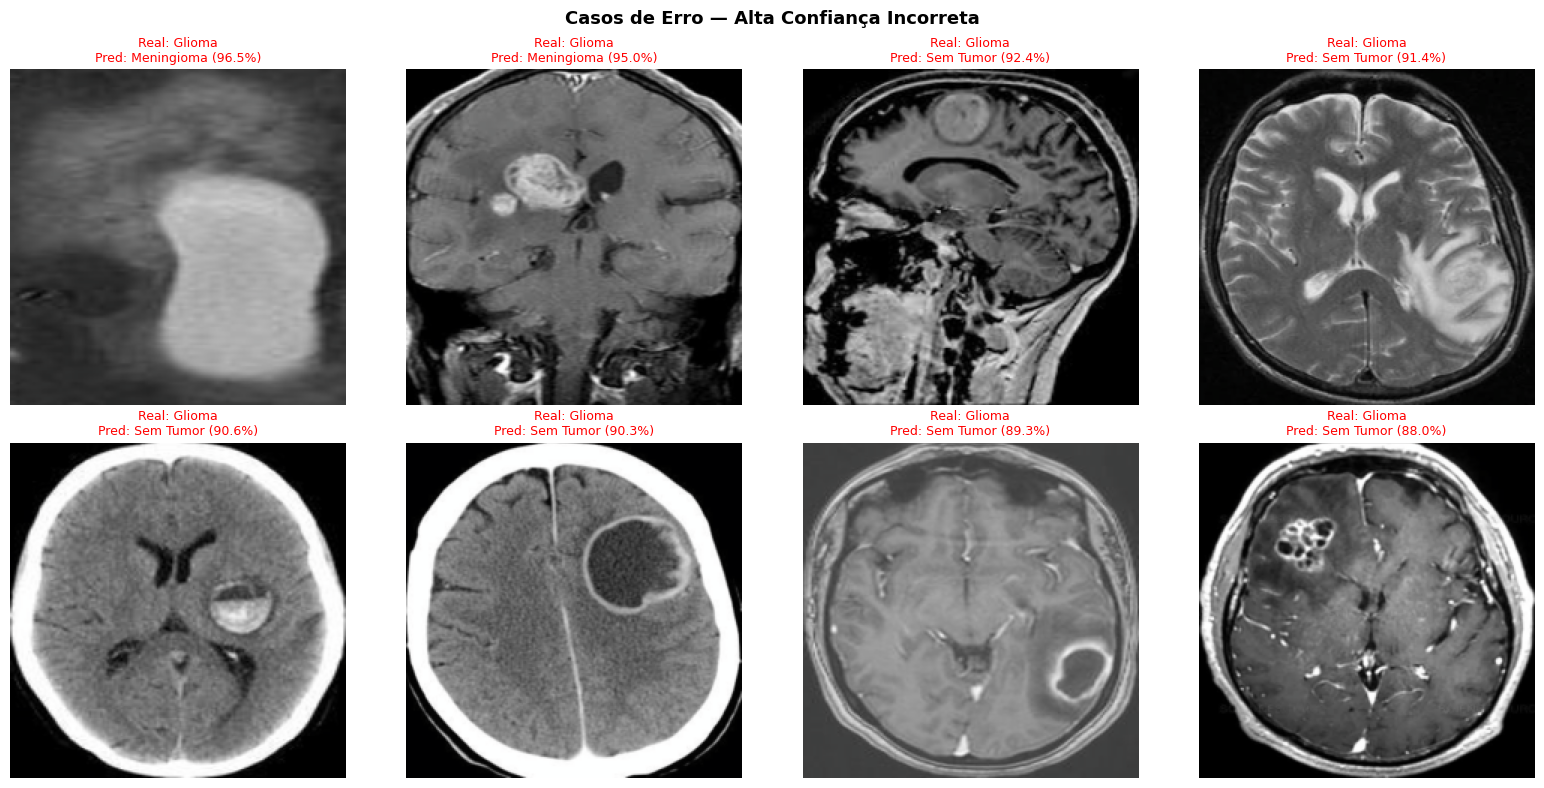

In [26]:
# Coletar amostras erradas com detalhes
cnn_model.eval()
errors = []  # (img_tensor, true_label, pred_label, confidence, path)

error_dataset = BrainTumorDataset(TEST_DIR, CLASSES, transform=test_transforms)

with torch.no_grad():
    for idx in range(len(error_dataset)):
        img_tensor, true_label = error_dataset[idx]
        logits = cnn_model(img_tensor.unsqueeze(0).to(DEVICE))
        probs  = torch.softmax(logits, dim=1)[0]
        pred   = logits.argmax(1).item()
        conf   = probs[pred].item()
        if pred != true_label:
            errors.append((img_tensor, true_label, pred, conf, error_dataset.samples[idx][0]))
        if len(errors) >= 50:
            break  # amostragem dos primeiros 50 erros para visualização

print(f'Erros encontrados (primeiros 50 avaliados): {len(errors)}')

# Mostra os 8 erros com maior confiança errada
errors_sorted = sorted(errors, key=lambda x: x[3], reverse=True)[:8]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Casos de Erro — Alta Confiança Incorreta', fontsize=13, fontweight='bold')

mean = np.array(IMAGENET_MEAN); std = np.array(IMAGENET_STD)
for ax, (img_t, true_l, pred_l, conf, path) in zip(axes.flatten(), errors_sorted):
    img_np = img_t.permute(1, 2, 0).numpy()
    img_np = np.clip(std * img_np + mean, 0, 1)
    ax.imshow(img_np)
    ax.set_title(
        f'Real: {CLASS_NAMES_PT[CLASSES[true_l]]}\n'
        f'Pred: {CLASS_NAMES_PT[CLASSES[pred_l]]} ({conf:.1%})',
        fontsize=9, color='red'
    )
    ax.axis('off')

plt.tight_layout()
plt.savefig('analise_erros.png', dpi=150, bbox_inches='tight')
plt.show()

### 8 Exportar o Modelo Treinado

In [ ]:
# Salva apenas os pesos para otimizar o tamanho do arquivo
torch.save(cnn_model.state_dict(), CKPT_PATH)